# Walk or talk? — project outline

**Project outline, 02805 Social Graphs and Interactions (2026). A first sketch around one topic, not a decided project: the research question, the datasets, the figures and the story are all still open.**

**The question this sketch tries out.** In the 2026 midterms the Democrats won the House by a wide margin. Among Republican House members who stood for re-election: did the ones who *worked* with Democrats (network), or the ones who *sounded* less partisan (language), hold up better?

| Half of the course | What we build | What it measures |
|---|---|---|
| Networks | cosponsorship network of the 119th House | **walk**: how much of a member's cooperation crosses the aisle |
| Language | floor speeches from the Congressional Record | **talk**: how Republican a member's vocabulary sounds |
| Ground truth | 2026 district results | how far each Republican ran ahead of or behind their district's lean |

The data are downloaded and cleaned by the scripts in `scripts/` (see `readme.md`); this notebook starts from the tables in `data/processed/`. Every number quoted below is computed in a cell.

**Order matters.** Sections 3–5 build the walk and talk scores *without using the election*; the results are joined only in section 6. The main definitions were written before the first run. A few robustness variants were added after a first run on partial data had already shown a verdict: `readme.md` §7 lists exactly which.

## 1. Setup and the choices we made

In [1]:
import sys, re, json, collections
import numpy as np, pandas as pd, networkx as nx, matplotlib, matplotlib.pyplot as plt, scipy, sklearn
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import normalized_mutual_info_score

for name, mod in [("python", sys), ("numpy", np), ("pandas", pd), ("networkx", nx), ("matplotlib", matplotlib), ("scipy", scipy), ("scikit-learn", sklearn)]:
    print(f"{name:<13}{mod.version.split()[0] if mod is sys else mod.__version__}")

DATA, FIG = "data/processed", "figures"
SEED = 2805
rng = np.random.default_rng(SEED)

# ---- every modelling choice in one place (ours to change; sections 4.2, 5 and 6.1 show what moves when we do) ----
BILL_TYPES         = ("hr", "hjres")   # walk: bills and joint resolutions; simple/concurrent resolutions are mostly commemorative
MAX_COSPONSORS     = None              # walk: no cap on bill size in the main version (a cap of 50 is a variant)
MIN_COSPONSORSHIPS = 10                # walk: a member needs at least this many cosponsorships to get a score
MIN_TURN_WORDS     = 50                # talk: ignore turns shorter than this (procedure, interjections)
MIN_MEMBER_WORDS   = 3000              # talk: a member needs at least this many words to get a score
MIN_WORD_MEMBERS   = 20                # talk: keep a word only if at least this many members use it
SMOOTH             = 0.1               # talk: added to both rates (per 10,000 words) before taking the ratio
N_SHUFFLES         = 5000              # size of every shuffle null
RED, BLUE, GREY    = "#c0392b", "#2c6fbb", "#8a8a8a"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left"})

python       3.14.6
numpy        2.4.6
pandas       3.0.3
networkx     3.6.1
matplotlib   3.11.0
scipy        1.18.0
scikit-learn 1.9.0


## 2. The data

Five tables, all keyed by the members' **Bioguide ID** (the identifier every source shares), so no joining by name is needed in the notebook.

In [2]:
members    = pd.read_csv(f"{DATA}/members.csv").set_index("bioguide")
bills      = pd.read_parquet(f"{DATA}/bills.parquet")
cosponsors = pd.read_parquet(f"{DATA}/cosponsors.parquet")
speeches   = pd.read_parquet(f"{DATA}/speeches.parquet")
districts  = pd.read_csv(f"{DATA}/districts.csv")
incumbents = pd.read_csv(f"{DATA}/incumbents.csv")
index      = pd.read_csv("data/raw/record_index.csv")          # the only raw file the notebook needs

party = members.party
days_all, days_have = index.day.nunique(), speeches.day.nunique()
coverage = json.load(open(f"{DATA}/record_coverage.json"))      # written by scripts/04_parse_record.py
items_all, items_have = coverage["items_in_index"], coverage["items_parsed"]
RECORD_COMPLETE = items_have == items_all

print(f"{'table':<12}{'rows':>9}   what one row is")
for name, df, what in [("members", members, "a House member of the 119th Congress"), ("bills", bills, "a House bill or resolution"),
                       ("cosponsors", cosponsors, "one member signing on to one bill"), ("speeches", speeches, "one speaker turn in the Record"),
                       ("districts", districts, "a congressional district, 2026 result"), ("incumbents", incumbents, "a sitting member and their fate")]:
    print(f"{name:<12}{len(df):>9,}   {what}")
print(f"\nmembers by party: {party.value_counts().to_dict()}")
print(f"Record items downloaded: {items_have:,} of {items_all:,} ({items_have/items_all:.0%}); days with text: {days_have} of {days_all}")
print("Record text is COMPLETE" if RECORD_COMPLETE else "!! Record text is PARTIAL: every talk number below is provisional")
print(f"words attached to a member: {speeches.n_words.sum():,}")

table            rows   what one row is
members           451   a House member of the 119th Congress
bills          12,987   a House bill or resolution
cosponsors    149,015   one member signing on to one bill
speeches       35,629   one speaker turn in the Record
districts         435   a congressional district, 2026 result
incumbents        424   a sitting member and their fate

members by party: {'R': 226, 'D': 224, 'I': 1}
Record items downloaded: 31,421 of 31,421 (100%); days with text: 303 of 339
Record text is COMPLETE
words attached to a member: 8,421,560


## 3. Who we study, and the election result (kept aside until section 6)

**Population:** Republican House members who were on the November ballot as the only incumbent, against a Democrat, in a race that has been called.

Everyone else is listed, not silently dropped. The outcome is the two-party margin from raw vote counts, in percentage points: positive means the Republican won.

In [3]:
inc = incumbents.merge(districts, on=["state", "district"], how="left").set_index("bioguide")
inc["party"] = party.reindex(inc.index)
inc["name"]  = members.name.reindex(inc.index)
inc["last"]  = members["last"].str.title().reindex(inc.index)
n_inc = inc.groupby(["state", "district"]).size()
inc["n_incumbents"] = [n_inc[(s, d)] for s, d in zip(inc.state, inc.district)]

rep = inc[inc.party == "R"].copy()
rep["reason_out"] = np.select(
    [rep.fate.isin(["did not run", "lost primary"]), rep.n_incumbents > 1, (rep.n_rep != 1) | (rep.n_dem != 1), rep.winner.isna()],
    ["did not run or lost the primary", "two incumbents in one district", "not one Republican against one Democrat", "race not called"], default="")
print("Republican members on the Wikipedia page:", len(rep))
print(rep.reason_out.replace("", "IN THE STUDY").value_counts().to_string(), "\n")

pop = rep[rep.reason_out == ""].copy()
pop["won"]    = pop.winner == "gop"
pop["margin"] = 100 * (pop.rep_votes - pop.dem_votes) / (pop.rep_votes + pop.dem_votes)

# cross-check the two sources on who won
wiki_says = pop.fate.map({"re-elected": True, "lost general": False})
disagree = pop[wiki_says.notna() & (wiki_says != pop.won)]
print(f"study population: {len(pop)} Republicans | won {int(pop.won.sum())}, lost {int((~pop.won).sum())}")
print(f"NBC and Wikipedia disagree on the winner in {len(disagree)} races" + ("" if disagree.empty else ":\n" + disagree[["name", "state", "district", "fate", "winner"]].to_string()))
print(f"races Wikipedia had not updated ('uncalled' there) but NBC has called: {int((pop.fate == 'uncalled').sum())}")
print(f"share of votes counted: median {pop.pct_in.median():.0f}%, minimum {pop.pct_in.min():.0f}%")
tx1 = districts[(districts.state == "TX") & (districts.district == 1)].iloc[0]
assert (tx1.rep_votes, tx1.dem_votes) == (181987, 81598), "TX-1 spot check failed"
lost_out = rep[(rep.fate == "lost general") & (rep.reason_out != "")]
print(f"Republicans who lost in November but are outside the study: {len(lost_out)}" + ("" if lost_out.empty else " — " + "; ".join(f"{r.name} ({r.state}-{r.district}: {r.reason_out})" for r in lost_out.itertuples())))
assert pop.index.is_unique and pop.lean.notna().all() and pop.margin.notna().all()

Republican members on the Wikipedia page: 214
reason_out
IN THE STUDY                               162
did not run or lost the primary             40
race not called                              8
not one Republican against one Democrat      4 

study population: 162 Republicans | won 132, lost 30
NBC and Wikipedia disagree on the winner in 0 races
races Wikipedia had not updated ('uncalled' there) but NBC has called: 1
share of votes counted: median 99%, minimum 77%
Republicans who lost in November but are outside the study: 4 — Young Kim (CA-40: not one Republican against one Democrat); Lauren Boebert (CO-4: race not called); Gregory F. Murphy (NC-3: race not called); Virginia Foxx (NC-5: race not called)


## 4. Walk — the cosponsorship network

A member **cosponsors** a bill by signing on to a colleague's proposal. We draw a directed link *cosponsor → sponsor*, weighted by the number of bills. This is a network of cooperation that members chose themselves, unlike roll-call votes, which the leadership schedules.

**Walk score** = of all the cosponsorships a member made, the share that went to a sponsor of the other party.

In [4]:
def cosponsor_links(types=BILL_TYPES, cap=MAX_COSPONSORS):
    b = bills[bills.type.isin(types)]
    if cap is not None:
        b = b[b.n_cosponsors <= cap]
    c = cosponsors[~cosponsors.withdrawn].merge(b[["bill_id", "sponsor"]], on="bill_id")
    c = c[c.cosponsor.isin(members.index) & c.sponsor.isin(members.index) & (c.cosponsor != c.sponsor)]
    return c.assign(cross=party.reindex(c.cosponsor).values != party.reindex(c.sponsor).values)

def walk_score(links, both_directions=False):
    out = links.groupby("cosponsor").cross.agg(["sum", "size"])
    if both_directions:                                     # also count cosponsors a member received
        inn = links.groupby("sponsor").cross.agg(["sum", "size"])
        out = out.add(inn, fill_value=0)
    return (out["sum"] / out["size"]).where(out["size"] >= MIN_COSPONSORSHIPS)

links = cosponsor_links()
edges = links.groupby(["cosponsor", "sponsor"]).size().rename("weight").reset_index()
G = nx.DiGraph()
G.add_nodes_from(members.index)
G.add_weighted_edges_from(edges.itertuples(index=False))
G.remove_nodes_from([n for n in list(G) if G.degree(n) == 0])
U = nx.Graph()
for u, v, w in G.edges(data="weight"):
    U.add_edge(u, v, weight=w + (U[u][v]["weight"] if U.has_edge(u, v) else 0))

n, m = G.number_of_nodes(), G.number_of_edges()
print(f"bills used: {links.bill_id.nunique():,} ({', '.join(BILL_TYPES)}) | cosponsorships: {len(links):,}")
print(f"network: n = {n} members, m = {m:,} directed links, density {nx.density(G):.2f}, reciprocity {nx.reciprocity(G):.2f}")
print(f"cosponsorships per member: median {links.groupby('cosponsor').size().median():.0f}")

bills used: 8,714 (hr, hjres) | cosponsorships: 126,687
network: n = 450 members, m = 62,292 directed links, density 0.31, reciprocity 0.50
cosponsorships per member: median 252


### 4.1 Is the network split by party? Against a null.

The House is close to half and half, so *if party did not matter* about half of all cosponsorships would cross the aisle. We test that by shuffling the party labels over the members (the wiring stays as it is).

In [5]:
ci, si = members.index.get_indexer(links.cosponsor), members.index.get_indexer(links.sponsor)
lab = (party == "R").values
obs_cross = links.cross.mean()
null_cross = np.array([(p[ci] != p[si]).mean() for p in (rng.permutation(lab) for _ in range(1000))])
print(f"cross-party share of cosponsorships: observed {obs_cross:.3f} | label-shuffle null {null_cross.mean():.3f} ± {null_cross.std():.3f}"
      f" | z = {(obs_cross - null_cross.mean()) / null_cross.std():.0f}")

comms = nx.community.louvain_communities(U, weight="weight", seed=SEED)
comm_of = {v: i for i, c in enumerate(comms) for v in c}
nodes = list(U)
two_party = [n_ for n_ in nodes if party[n_] in "RD"]
Q_louvain = nx.community.modularity(U, comms, weight="weight")
Q_party   = nx.community.modularity(U, [{v for v in nodes if party[v] == "R"}, {v for v in nodes if party[v] != "R"}], weight="weight")
nmi = normalized_mutual_info_score([party[v] for v in two_party], [comm_of[v] for v in two_party])
print(f"Louvain (seed {SEED}): {len(comms)} communities, modularity Q = {Q_louvain:.3f} | Q of the plain party split = {Q_party:.3f}")
rng_q = np.random.default_rng(SEED + 1)                      # own stream: the later shuffles stay reproducible
is_R = np.array([party[v] == "R" for v in nodes])
Q_null = np.array([nx.community.modularity(U, [set(np.array(nodes)[q]), set(np.array(nodes)[~q])], weight="weight")
                   for q in (rng_q.permutation(is_R) for _ in range(200))])
print(f"null for the party split (party labels shuffled 200 times): Q = {Q_null.mean():.3f} ± {Q_null.std():.3f}, so z = {(Q_party - Q_null.mean()) / Q_null.std():.0f}")
print(f"NMI between Louvain communities and party: {nmi:.2f}")
print(pd.crosstab(pd.Series({v: comm_of[v] for v in nodes}, name="community"), party.reindex(nodes)).to_string())

cross-party share of cosponsorships: observed 0.211 | label-shuffle null 0.501 ± 0.003 | z = -110
Louvain (seed 2805): 2 communities, modularity Q = 0.292 | Q of the plain party split = 0.269


null for the party split (party labels shuffled 200 times): Q = -0.002 ± 0.003, so z = 106
NMI between Louvain communities and party: 0.79
party        D  I    R
community             
0          208  0    1
1           16  1  224


### 4.2 The walk score, and three checks on it

* **Does the definition matter?** Three variants: all four bill types, only bills with at most 50 cosponsors (dropping the mass sign-ons), and counting received cosponsors too.
* **Second method.** Voteview's NOMINATE score places members left–right from their *roll-call votes*, a different behaviour measured by other people. If walk captures something real, Republicans who cross the aisle more should sit closer to the centre.

In [6]:
walk = walk_score(links).rename("walk")
variants = pd.DataFrame({
    "main (hr + hjres)":        walk,
    "all four bill types":      walk_score(cosponsor_links(types=("hr", "hjres", "hres", "hconres"))),
    "bills with ≤ 50 cosponsors": walk_score(cosponsor_links(cap=50)),
    "given + received":         walk_score(links, both_directions=True)})
R_ids, D_ids = members.index[party == "R"], members.index[party == "D"]

print(f"walk score: {walk.notna().sum()} members scored")
print(f"{'':<28}{'Republicans':>14}{'Democrats':>12}")
print(f"{'median walk':<28}{walk.reindex(R_ids).median():>14.3f}{walk.reindex(D_ids).median():>12.3f}")
print(f"{'10th–90th percentile':<28}{walk.reindex(R_ids).quantile(.1):>8.3f}–{walk.reindex(R_ids).quantile(.9):.3f}{walk.reindex(D_ids).quantile(.1):>6.3f}–{walk.reindex(D_ids).quantile(.9):.3f}")
print("\nSpearman correlation with the main score, Republicans only:")
for col in variants.columns[1:]:
    ok = variants.loc[variants.index.intersection(R_ids), ["main (hr + hjres)", col]].dropna()
    print(f"  {col:<28}{spearmanr(ok.iloc[:, 0], ok.iloc[:, 1])[0]:>6.2f}   (n = {len(ok)})")

print("\nSecond method — walk against NOMINATE (first dimension, higher = more conservative):")
for label, ids in [("Republicans", R_ids), ("Democrats", D_ids)]:
    ok = pd.concat([walk, members.nominate_dim1], axis=1).reindex(ids).dropna()
    rho, p = spearmanr(ok.walk, ok.nominate_dim1)
    print(f"  {label:<12} Spearman ρ = {rho:+.2f}  (n = {len(ok)}, p = {p:.1e})")

walk score: 447 members scored
                               Republicans   Democrats
median walk                          0.110       0.200
10th–90th percentile           0.035–0.268 0.097–0.400

Spearman correlation with the main score, Republicans only:
  all four bill types           0.99   (n = 223)
  bills with ≤ 50 cosponsors    0.96   (n = 222)
  given + received              0.79   (n = 223)

Second method — walk against NOMINATE (first dimension, higher = more conservative):
  Republicans  Spearman ρ = -0.79  (n = 223, p = 3.0e-48)
  Democrats    Spearman ρ = +0.73  (n = 223, p = 6.1e-38)


## 5. Talk — how Republican does a member sound?

Built the way the week-6 comparison figure is built: count each word's rate per 10,000 words in the two groups and compare.

1. Keep turns of at least `MIN_TURN_WORDS` words; lower-case; letters only.
2. Remove ordinary stopwords, **procedural House language** (the majority party manages bills on the floor, so "I move to suspend the rules" would otherwise count as a Republican phrase), and **members' names, states and months** (the "ann / olympics" trap in the course figure).
3. A word's rate in a party is the *average over that party's members* of the member's own rate, so one very talkative member cannot set the party's vocabulary.
4. Word partisanship = log₂ of (Republican rate / Democratic rate), with a small constant added to both.
5. A member's **talk score** is the average partisanship of the words they use — computed with *their own speeches left out* of the party rates, so nobody is scored against their own words.

In [7]:
PROCEDURAL = set('''speaker madam mister chair chairman chairwoman gentleman gentlewoman gentlelady yield yields yielding yielded
    time balance reserve reserves consume unanimous consent rise rises minute minutes hour bill bills resolution amendment
    amendments committee subcommittee house senate congress congressional colleague colleagues thank thanks urge support
    vote votes voting legislation legislative motion suspend rules pass passage revise extend remarks extraneous material
    days day members member act title section pursuant clerk rule order ordered objection question previous agreed ayes nays
    yeas recorded demand postponed proceedings further request recognize recognized ranking distinguished friend
    representative representatives rep sen senator today want would like also one may shall mrs dr hon res con'''.split())
MONTHS = set("january february march april may june july august september october november december monday tuesday wednesday thursday friday saturday sunday".split())
name_words  = {w for col in ("first", "last", "name") for s in members[col].dropna() for w in re.findall(r"[a-z]{3,}", s.lower())}
STATE_NAMES = '''alabama alaska arizona arkansas california colorado connecticut delaware florida georgia hawaii idaho illinois indiana
    iowa kansas kentucky louisiana maine maryland massachusetts michigan minnesota mississippi missouri montana nebraska nevada
    hampshire jersey mexico york carolina dakota ohio oklahoma oregon pennsylvania rhode island tennessee texas utah vermont
    virginia washington wisconsin wyoming north south west new'''.split()
# names that are also ordinary political words stay in the vocabulary
KEEP = {"tax", "price", "rich", "young", "green", "white", "black", "brown", "law", "bacon", "energy", "freedom", "justice", "border", "trade", "bill"} - PROCEDURAL
STOP = (set(ENGLISH_STOP_WORDS) | PROCEDURAL | MONTHS | set(STATE_NAMES) | name_words) - KEEP

sp = speeches[speeches.n_words >= MIN_TURN_WORDS]
docs = sp.groupby("bioguide").text.agg(" ".join)
words_per_member = sp.groupby("bioguide").n_words.sum()
cv = CountVectorizer(token_pattern=r"(?u)\b[a-z]{3,}\b", lowercase=True, stop_words=list(STOP), min_df=MIN_WORD_MEMBERS)
X = cv.fit_transform(docs).toarray().astype(float)
vocab = np.array(cv.get_feature_names_out())
rates = 1e4 * X / X.sum(1, keepdims=True)                      # each member's use per 10,000 kept words

scored = (words_per_member.reindex(docs.index) >= MIN_MEMBER_WORDS).values
isR, isD = (party.reindex(docs.index) == "R").values & scored, (party.reindex(docs.index) == "D").values & scored
rate_R, rate_D = rates[isR].mean(0), rates[isD].mean(0)
partisanship = np.log2((rate_R + SMOOTH) / (rate_D + SMOOTH))

print(f"turns kept: {len(sp):,} of {len(speeches):,} | members with text: {len(docs)} | vocabulary: {len(vocab):,} words")
print(f"members with ≥ {MIN_MEMBER_WORDS:,} words (scored): {int(isR.sum())} Republicans, {int(isD.sum())} Democrats")
print(f"words per scored member: median {int(words_per_member[docs.index[scored]].median()):,}")
order = np.argsort(partisanship)
print("\nmost Republican words:", ", ".join(vocab[order[::-1][:40]]))
print("\nmost Democratic words:", ", ".join(vocab[order[:40]]))

turns kept: 24,860 of 35,629 | members with text: 446 | vocabulary: 9,337 words
members with ≥ 3,000 words (scored): 208 Republicans, 206 Democrats
words per scored member: median 12,702

most Republican words: aliens, unborn, ffa, ccp, alien, guam, laken, omaha, bureaucrats, bless, baseload, bodied, warfighters, radical, cartels, biden, sheriff, bureaucracy, illegals, obamacare, maduro, confucius, wolf, fury, wasteful, burdensome, communist, hezbollah, jacksonville, lord, dominance, cattle, border, moses, graham, unleashing, lexington, minors, conservative, abortions

most Democratic words: ugly, puerto, musk, maternal, elon, billionaire, black, cruelty, ucla, disparities, rico, billionaires, wealthiest, tariffs, lgbtq, chicago, latino, racial, polluters, bronx, cruel, reproductive, richest, masked, diversity, selma, betrayal, african, richer, usaid, las, equality, hungry, racism, gutting, undocumented, los, asian, gut, artists


**Read before believing.** The lists above are the first thing to check by eye: each word should be about politics, not about procedure, a person or a place. Any that are not go into the stop lists above — *before* section 6, never after.

The figure is the course's two-group comparison: each dot is a word, Republican rate across, Democratic rate up, both on log axes. Words on the diagonal are shared.

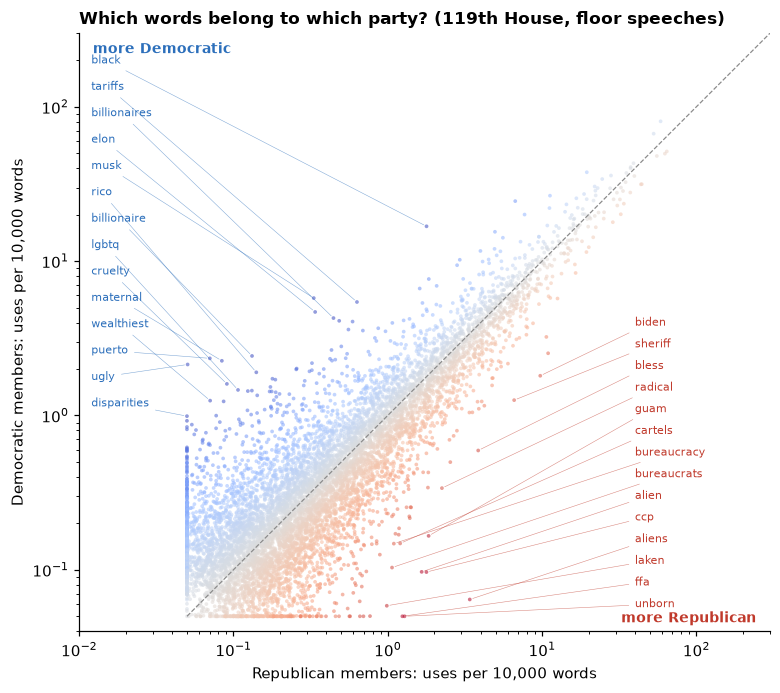

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 6.4))
lo = 0.05
xr, yd = np.maximum(rate_R, lo), np.maximum(rate_D, lo)
ax.scatter(xr, yd, s=6, c=partisanship, cmap="coolwarm", vmin=-3, vmax=3, alpha=.55, linewidths=0)
ax.plot([lo, 300], [lo, 300], color=GREY, lw=.8, ls="--")
ax.set(xscale="log", yscale="log", xlim=(0.01, 300), ylim=(lo * .8, 300),
       xlabel="Republican members: uses per 10,000 words", ylabel="Democratic members: uses per 10,000 words",
       title="Which words belong to which party? (119th House, floor speeches)")
common = (rate_R + rate_D) > 1.0                                  # label only words that are actually used
for idx, colour, ha, lx in [(order[::-1], RED, "left", 40), (order, BLUE, "left", 0.012)]:
    shown = sorted([i for i in idx if common[i]][:14], key=lambda i: yd[i] if colour == RED else xr[i])
    ys = np.geomspace(0.06, 4, len(shown)) if colour == RED else np.geomspace(1.2, 200, len(shown))
    for i, y in zip(shown, ys):                                # labels in a tidy column, joined to their dot by a hairline
        ax.annotate(vocab[i], (xr[i], yd[i]), xytext=(lx, y), fontsize=7.5, color=colour, ha=ha, va="center",
                    arrowprops=dict(arrowstyle="-", color=colour, lw=.35, alpha=.6), annotation_clip=False)
ax.text(.02, .985, "more Democratic", transform=ax.transAxes, color=BLUE, fontsize=9, va="top", weight="bold")
ax.text(.98, .015, "more Republican", transform=ax.transAxes, color=RED, fontsize=9, ha="right", weight="bold")
fig.tight_layout(); fig.savefig(f"{FIG}/fig1_party_words.png"); plt.show()

In [9]:
def talk_from_counts(C, ids, n_words, min_words=MIN_MEMBER_WORDS):
    # Talk score from a members × words count table. Each member's own speeches are held out of their
    # party's rates. Scale: average Democrat = −1, average Republican = +1.
    r_ = 1e4 * C / np.maximum(C.sum(1, keepdims=True), 1)
    ok = (n_words.reindex(ids).fillna(0) >= min_words).values
    p_ = party.reindex(ids).values
    mR, mD = ok & (p_ == "R"), ok & (p_ == "D")
    sR, sD = r_[mR].sum(0), r_[mD].sum(0)
    raw = np.full(len(ids), np.nan)
    for i in np.flatnonzero(ok):
        r = (sR - r_[i]) / (mR.sum() - 1) if mR[i] else sR / mR.sum()
        d = (sD - r_[i]) / (mD.sum() - 1) if mD[i] else sD / mD.sum()
        raw[i] = r_[i] @ np.log2((r + SMOOTH) / (d + SMOOTH)) / r_[i].sum()
    mid, half = (raw[mR].mean() + raw[mD].mean()) / 2, (raw[mR].mean() - raw[mD].mean()) / 2
    return pd.Series((raw - mid) / half, index=ids)

talk = talk_from_counts(X, docs.index, words_per_member).rename("talk")
right_side = ((talk[isR] > 0).sum() + (talk[isD] < 0).sum()) / (isR.sum() + isD.sum())
print(f"held-out check: the sign of the talk score matches the member's party for {right_side:.1%} of {isR.sum() + isD.sum()} members")
print(f"Republicans who sound Democratic (talk < 0): {int((talk[isR] < 0).sum())} | Democrats who sound Republican (talk > 0): {int((talk[isD] > 0).sum())}")

# two variants, both still without the election
spH = sp[sp.section == "H"]                                     # (1) spoken floor turns only, no written Extensions of Remarks
docsH = spH.groupby("bioguide").text.agg(" ".join)
talk_floor = talk_from_counts(cv.transform(docsH).toarray().astype(float), docsH.index, spH.groupby("bioguide").n_words.sum()).rename("talk_floor")
# (2) places, people and clubs that turned up among the 40 most partisan words when we read the lists above
READ_OUT = ["guam", "omaha", "jacksonville", "lexington", "puerto", "rico", "chicago", "bronx", "ucla", "las", "los", "graham", "moses", "ffa"]
keep_cols = ~np.isin(vocab, READ_OUT)
talk_clean = talk_from_counts(X[:, keep_cols], docs.index, words_per_member).rename("talk_clean")
share_E = sp[sp.section == "E"].n_words.sum() / sp.n_words.sum()
print(f"\nwritten Extensions of Remarks are {share_E:.0%} of all words")
for label, v in [("floor turns only", talk_floor), (f"{len(READ_OUT)} place/person words removed", talk_clean)]:
    cmp = pd.concat([talk, v], axis=1).reindex(members.index[party == "R"]).dropna()
    print(f"  talk variant '{label}' vs main talk, Republicans: ρ = {spearmanr(cmp.iloc[:, 0], cmp.iloc[:, 1])[0]:.2f} (n = {len(cmp)})")
show = pd.concat([talk, members[["name", "party", "state"]]], axis=1).dropna(subset=["talk"])
print("\nmost Democratic-sounding Republicans:\n", show[show.party == "R"].nsmallest(6, "talk").round(2).to_string(index=False))
print("\nmost Republican-sounding Republicans:\n", show[show.party == "R"].nlargest(6, "talk").round(2).to_string(index=False))

held-out check: the sign of the talk score matches the member's party for 92.5% of 414 members
Republicans who sound Democratic (talk < 0): 6 | Democrats who sound Republican (talk > 0): 25



written Extensions of Remarks are 27% of all words
  talk variant 'floor turns only' vs main talk, Republicans: ρ = 0.74 (n = 179)
  talk variant '14 place/person words removed' vs main talk, Republicans: ρ = 1.00 (n = 208)

most Democratic-sounding Republicans:
  talk                 name party state
-0.52         Dan Crenshaw     R    TX
-0.49     David Schweikert     R    AZ
-0.45       Glenn Grothman     R    WI
-0.21        Steve Scalise     R    LA
-0.05    Michael T. McCaul     R    TX
-0.01 Maria Elvira Salazar     R    FL

most Republican-sounding Republicans:
  talk             name party state
 2.83    Matt Van Epps     R    TN
 2.18   Dale W. Strong     R    AL
 1.94      Jake Ellzey     R    TX
 1.91       Pat Fallon     R    TX
 1.91 Barry Loudermilk     R    GA
 1.85      Trent Kelly     R    MS


### 5.1 Do walk and talk agree?

This is the part that needs no election. If the two halves of the course measured the same thing, the dots would fall on a line. Where they do not, we may have members who **sound loyal but cooperate**, or **cooperate little but sound unlike their party** — or we may be looking at noise in the talk score. Two checks below help tell which: how well two halves of a member's speeches agree, and how talk changes across the party from least to most conservative.

Republicans with both scores: 206 | Spearman ρ(walk, talk) = -0.20 (p = 4.5e-03)
for comparison, ρ(talk, NOMINATE) = +0.24



split-half check, Republicans (odd days vs even days, n = 185): ρ = 0.41 → reliability of the full score about 0.58 (Spearman–Brown)

mean talk and walk of Republicans by fifth of the roll-call ideology score:
                    talk       walk     
                    mean size  mean size
nominate_dim1                           
least conservative  0.78   44  0.26   44
2                   1.00   39  0.15   39
3                   1.08   41  0.12   41
4                   1.11   42  0.09   42
most conservative   1.09   40  0.05   40

sound partisan, cooperate anyway:
                name state  walk  talk
Andrew R. Garbarino    NY  0.34  1.54
  Stephanie I. Bice    OK  0.17  1.79
       Zachary Nunn    IA  0.46  1.27
 John H. Rutherford    FL  0.23  1.44
     James R. Baird    IN  0.18  1.60
         Gabe Evans    CO  0.23  1.37

sound moderate, cooperate little:
                   name state  walk  talk
              Chip Roy    TX  0.02  0.27
          Ralph Norman    SC  0.02  0.57


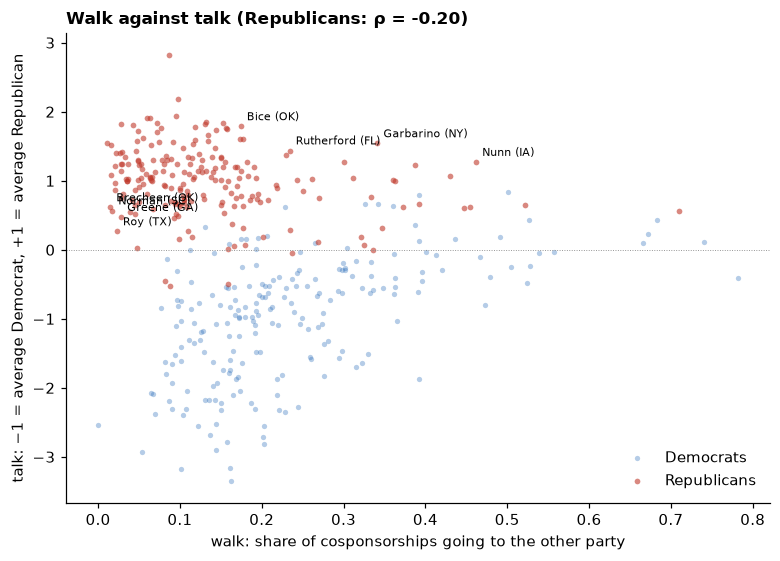

In [10]:
both = pd.concat([walk, talk, members[["name", "party", "state", "district", "nominate_dim1"]], members["last"].str.title()], axis=1).dropna(subset=["walk", "talk"])
bR = both[both.party == "R"].copy()
rho_wt, p_wt = spearmanr(bR.walk, bR.talk)
print(f"Republicans with both scores: {len(bR)} | Spearman ρ(walk, talk) = {rho_wt:+.2f} (p = {p_wt:.1e})")
print(f"for comparison, ρ(talk, NOMINATE) = {spearmanr(bR.talk, bR.nominate_dim1, nan_policy='omit')[0]:+.2f}")

# How much of the talk score is signal? Split every member's speeches into odd and even days and score each half.
day_rank = sp.day.map({d: k for k, d in enumerate(sorted(sp.day.unique()))})
halves = []
for parity in (0, 1):
    part = sp[day_rank % 2 == parity]
    dh = part.groupby("bioguide").text.agg(" ".join)
    halves.append(talk_from_counts(cv.transform(dh).toarray().astype(float), dh.index, part.groupby("bioguide").n_words.sum(), min_words=MIN_MEMBER_WORDS // 2))
sh = pd.concat(halves, axis=1).reindex(R_ids).dropna()
r_half = spearmanr(sh.iloc[:, 0], sh.iloc[:, 1])[0]
print(f"\nsplit-half check, Republicans (odd days vs even days, n = {len(sh)}): ρ = {r_half:.2f}"
      f" → reliability of the full score about {2 * r_half / (1 + r_half):.2f} (Spearman–Brown)")

# Is low talk a moderate thing or a both-ends thing? Mean talk across the party from least to most conservative.
q = pd.qcut(bR.nominate_dim1, 5, labels=["least conservative", "2", "3", "4", "most conservative"])
print("\nmean talk and walk of Republicans by fifth of the roll-call ideology score:")
print(bR.groupby(q, observed=True)[["talk", "walk"]].agg(["mean", "size"]).round(2).to_string())

bR["walk_rank"], bR["talk_rank"] = bR.walk.rank(pct=True), bR.talk.rank(pct=True)
bR["mismatch"] = bR.walk_rank - (1 - bR.talk_rank)             # > 0: cooperates more than their language suggests
quiet = bR.nlargest(6, "mismatch"); loud = bR.nsmallest(6, "mismatch")
print("\nsound partisan, cooperate anyway:\n", quiet[["name", "state", "walk", "talk"]].round(2).to_string(index=False))
print("\nsound moderate, cooperate little:\n", loud[["name", "state", "walk", "talk"]].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.2, 5.2))
bD = both[both.party == "D"]
ax.scatter(bD.walk, bD.talk, s=12, color=BLUE, alpha=.35, linewidths=0, label="Democrats")
ax.scatter(bR.walk, bR.talk, s=14, color=RED, alpha=.6, linewidths=0, label="Republicans")
ax.axhline(0, color=GREY, lw=.6, ls=":")
for r in pd.concat([quiet.head(4), loud.head(4)]).itertuples():
    ax.annotate(f"{r.last} ({r.state})", (r.walk, r.talk), xytext=(4, 4), textcoords="offset points", fontsize=7.5)
ax.set(xlabel="walk: share of cosponsorships going to the other party", ylabel="talk: −1 = average Democrat, +1 = average Republican",
       title=f"Walk against talk (Republicans: ρ = {rho_wt:+.2f})")
ax.legend(frameon=False, loc="lower right"); fig.tight_layout(); fig.savefig(f"{FIG}/fig2_walk_vs_talk.png"); plt.show()

### 5.2 The picture: a network wired by cooperation, coloured by language

Left: the cosponsorship network coloured by party. Right: the *same layout*, coloured by how each member sounds. Only each member's strongest ties are drawn, otherwise the picture is a solid block.

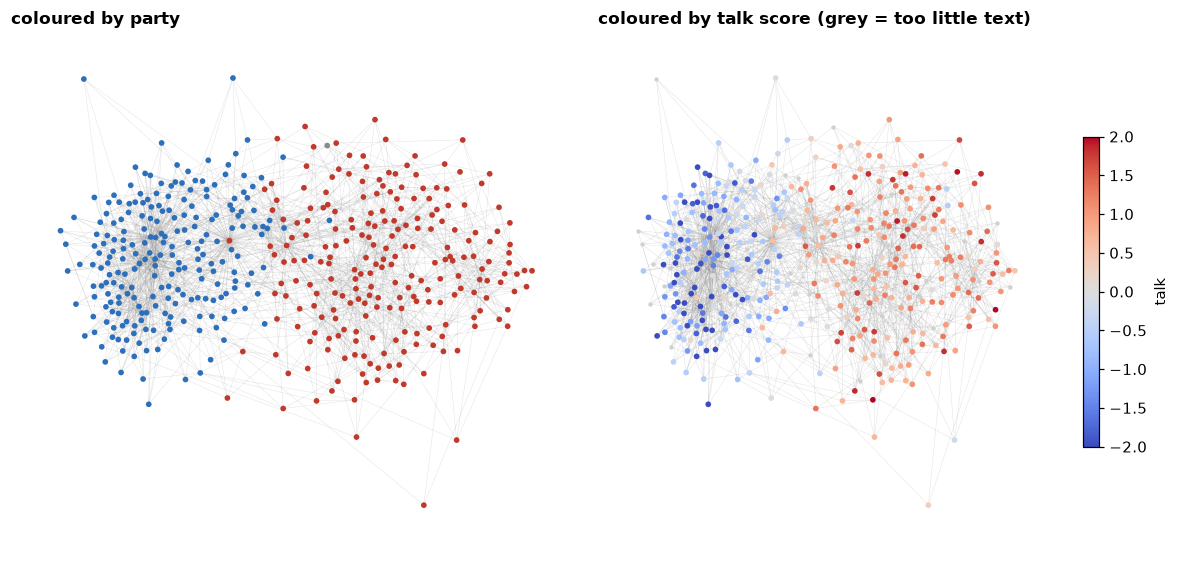

drawn: 450 members, 1,940 strongest ties (of 46,647)


In [11]:
strong = nx.Graph()
strong.add_nodes_from(U)
for v in U:                                                     # keep each member's 5 heaviest ties
    for u, d in sorted(U[v].items(), key=lambda kv: -kv[1]["weight"])[:5]:
        strong.add_edge(v, u, weight=d["weight"])
pos = nx.spring_layout(strong, weight="weight", seed=SEED, iterations=200, k=0.12)
nodes_ = list(strong)
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, title in zip(axes, ["coloured by party", "coloured by talk score (grey = too little text)"]):
    nx.draw_networkx_edges(strong, pos, ax=ax, width=.3, alpha=.25, edge_color=GREY)
    ax.set_title(title); ax.axis("off")
nx.draw_networkx_nodes(strong, pos, ax=axes[0], nodelist=nodes_, node_size=14, linewidths=0,
                       node_color=[RED if party[v] == "R" else BLUE if party[v] == "D" else GREY for v in nodes_])
has = [v for v in nodes_ if v in talk.index and not np.isnan(talk[v])]
nx.draw_networkx_nodes(strong, pos, ax=axes[1], nodelist=[v for v in nodes_ if v not in has], node_size=8, node_color="#d0d0d0", linewidths=0)
sc = nx.draw_networkx_nodes(strong, pos, ax=axes[1], nodelist=has, node_size=14, linewidths=0,
                            node_color=[talk[v] for v in has], cmap="coolwarm", vmin=-2, vmax=2)
fig.colorbar(sc, ax=axes[1], shrink=.6, label="talk")
fig.tight_layout(); fig.savefig(f"{FIG}/fig3_network_two_colourings.png"); plt.show()
print(f"drawn: {strong.number_of_nodes()} members, {strong.number_of_edges():,} strongest ties (of {U.number_of_edges():,})")

## 6. The verdict — joining the election

Only now do the results meet the scores.

* **Overperformance** = a Republican's margin minus what their district's lean predicts (a straight-line fit of margin on lean, over the study population). Positive: ran ahead of the district.
* **Test:** Spearman correlation of overperformance with walk, and with talk.
* **Null:** shuffle overperformance among Republicans in districts of similar lean (five equal-sized lean groups), `N_SHUFFLES` times.
* **Rule fixed in advance:** if neither correlation falls outside the middle 95% of its null, the answer is *"no detectable relation"* and we report exactly that.

In [12]:
study = pop.join(walk).join(talk)
slope, intercept = np.polyfit(study.lean, study.margin, 1)
study["expected"] = intercept + slope * study.lean
study["over"] = study.margin - study.expected
r2 = np.corrcoef(study.lean, study.margin)[0, 1] ** 2
print(f"margin = {intercept:+.1f} {slope:+.2f} × lean   (R² = {r2:.2f}, n = {len(study)})")
print(f"an 'even' district is predicted at {intercept:+.1f} points for the Republican: the size of the wave in this group")
print(f"overperformance: sd {study.over.std():.1f} points, range {study.over.min():+.1f} to {study.over.max():+.1f}")
print(f"with a walk score: {int(study.walk.notna().sum())} | with a talk score: {int(study.talk.notna().sum())} | with both: {int((study.walk.notna() & study.talk.notna()).sum())}")

def shuffle_test(df, x, y="over", groups=5):
    d = df[[x, y, "lean"]].dropna()
    g = pd.qcut(d.lean.rank(method="first"), groups, labels=False).values
    obs = spearmanr(d[x], d[y])[0]
    yv, null = d[y].values.copy(), np.empty(N_SHUFFLES)
    idx = [np.flatnonzero(g == k) for k in range(groups)]
    for s in range(N_SHUFFLES):
        ys = yv.copy()
        for ix in idx:
            ys[ix] = yv[rng.permutation(ix)]
        null[s] = spearmanr(d[x], ys)[0]
    lo_, hi_ = np.quantile(null, [.025, .975])
    p = float((np.abs(null - null.mean()) >= abs(obs - null.mean())).mean())     # two-sided, from the centre of the null
    return dict(n=len(d), rho=obs, lo=lo_, hi=hi_, centre=null.mean(), p=p, outside=bool(obs < lo_ or obs > hi_))

tests = {"walk": shuffle_test(study, "walk"), "talk": shuffle_test(study, "talk")}
print(f"\n{'score':<6}{'n':>5}{'ρ with overperformance':>25}{'null 95% band':>20}{'p':>8}   outside the band?")
for k, t in tests.items():
    print(f"{k:<6}{t['n']:>5}{t['rho']:>+25.2f}{t['lo']:>+12.2f} to {t['hi']:+.2f}{t['p']:>8.3f}   {'YES' if t['outside'] else 'no'}")
hits = [k for k, t in tests.items() if t["outside"]]
VERDICT = (f"{' and '.join(hits)} falls outside its null band (see 6.1 for how well that holds up)" if hits
           else "no detectable relation (the pre-stated rule says: report a null)")
print("\nverdict:", VERDICT)

margin = -11.2 +1.87 × lean   (R² = 0.83, n = 162)
an 'even' district is predicted at -11.2 points for the Republican: the size of the wave in this group
overperformance: sd 6.0 points, range -26.6 to +16.7
with a walk score: 162 | with a talk score: 154 | with both: 154



score     n   ρ with overperformance       null 95% band       p   outside the band?
walk    162                    +0.14       -0.10 to +0.17   0.103   no
talk    154                    -0.20       -0.17 to +0.14   0.018   YES

verdict: talk falls outside its null band (see 6.1 for how well that holds up)


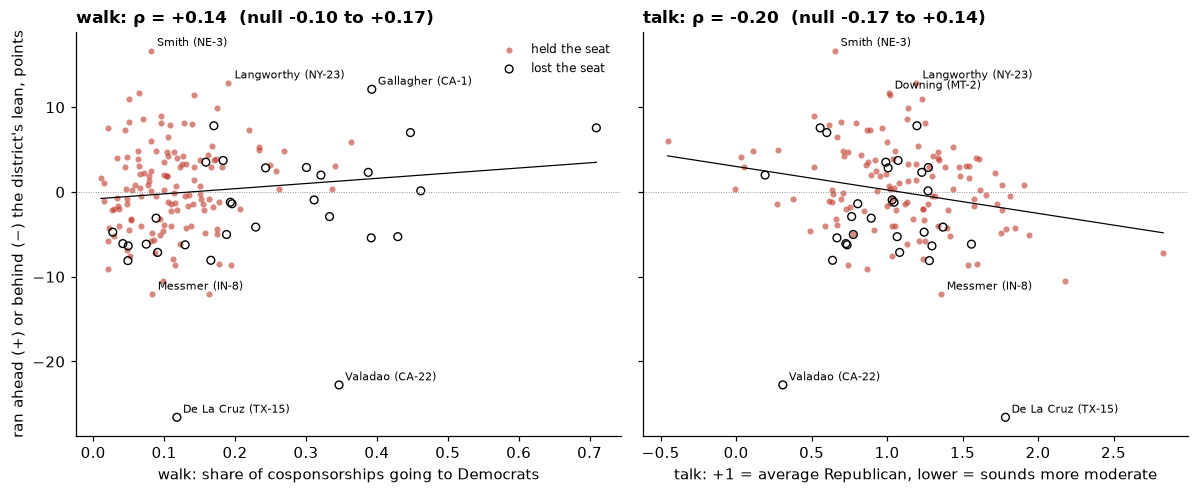

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, x, xl in zip(axes, ["walk", "talk"], ["walk: share of cosponsorships going to Democrats", "talk: +1 = average Republican, lower = sounds more moderate"]):
    d = study.dropna(subset=[x])
    ax.axhline(0, color=GREY, lw=.6, ls=":")
    ax.scatter(d[x][d.won], d.over[d.won], s=16, color=RED, alpha=.6, linewidths=0, label="held the seat")
    ax.scatter(d[x][~d.won], d.over[~d.won], s=26, facecolors="none", edgecolors="black", linewidths=.9, label="lost the seat")
    b, a = np.polyfit(d[x], d.over, 1); xs = np.linspace(d[x].min(), d[x].max(), 2)
    ax.plot(xs, a + b * xs, color="black", lw=.8)
    for r in pd.concat([d.nlargest(3, "over"), d.nsmallest(3, "over")]).itertuples():
        ax.annotate(f"{r.last} ({r.state}-{r.district})", (getattr(r, x), r.over), xytext=(4, 3), textcoords="offset points", fontsize=7)
    t = tests[x]
    ax.set(xlabel=xl, title=f"{x}: ρ = {t['rho']:+.2f}  (null {t['lo']:+.2f} to {t['hi']:+.2f})")
axes[0].set_ylabel("ran ahead (+) or behind (−) the district's lean, points"); axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIG}/fig4_verdict.png"); plt.show()

### 6.1 Does the verdict survive our own choices?

Things that could be driving it rather than the members themselves:

* **Redrawn districts.** Nine states changed their maps before this election. Whether the lean figures on the Wikipedia page describe the *new* lines is **not verified**, so we rerun without those states.
* **Win or lose instead of margin.** A blunter outcome: among competitive districts, did losers and survivors differ? Read this with the lean row: members in swing districts both cooperate more *and* lose more, so a raw gap in walk between losers and survivors is not an effect of walking.
* **The talk score itself.** Two other ways of building it (section 5): spoken floor turns only, and with the place and person words we found by reading the lists removed.
* **Both scores at once.** Walk and talk are correlated, so we also fit them together (standardised, with lean).

In [14]:
print("A. excluding the redrawn states:", ", ".join(sorted(study.state[study.redrawn_state].unique())))
for k in ("walk", "talk"):
    t = shuffle_test(study[~study.redrawn_state], k)
    print(f"   {k}: n = {t['n']}, ρ = {t['rho']:+.2f}, null {t['lo']:+.2f} to {t['hi']:+.2f}, p = {t['p']:.3f}")

comp = study[study.lean <= 10]
print(f"\nB. win or lose, districts leaning at most R+10: {len(comp)} members, {int((~comp.won).sum())} lost")
print(f"   {'':<10}{'held the seat':>15}{'lost the seat':>15}")
for k in ("walk", "talk", "lean"):
    print(f"   mean {k:<5}{comp[k][comp.won].mean():>15.3f}{comp[k][~comp.won].mean():>15.3f}")

print("\nC. other ways of building the talk score (added after the first partial-data run, see readme §7):")
for label, v in [("floor turns only", talk_floor), ("place/person words removed", talk_clean)]:
    t = shuffle_test(study.join(v), v.name)
    print(f"   {label:<28} n = {t['n']}, ρ = {t['rho']:+.2f}, null {t['lo']:+.2f} to {t['hi']:+.2f}, p = {t['p']:.3f}")

d = study.dropna(subset=["walk", "talk"])
Z = np.column_stack([np.ones(len(d))] + [(d[c] - d[c].mean()) / d[c].std() for c in ("lean", "walk", "talk")])
coef = np.linalg.lstsq(Z, d.margin.values, rcond=None)[0]
print(f"\nD. margin on lean, walk and talk together (n = {len(d)}; points of margin per standard deviation):")
print(f"   lean {coef[1]:+.1f} | walk {coef[2]:+.1f} | talk {coef[3]:+.1f}")

A. excluding the redrawn states: AL, CA, FL, NC, OH, TN, TX, UT


   walk: n = 99, ρ = +0.09, null -0.19 to +0.15, p = 0.223


   talk: n = 95, ρ = -0.16, null -0.22 to +0.17, p = 0.168

B. win or lose, districts leaning at most R+10: 72 members, 30 lost
               held the seat  lost the seat
   mean walk           0.135          0.241
   mean talk           1.001          0.982
   mean lean           8.095          3.033

C. other ways of building the talk score (added after the first partial-data run, see readme §7):


   floor turns only             n = 133, ρ = -0.23, null -0.16 to +0.16, p = 0.006


   place/person words removed   n = 154, ρ = -0.19, null -0.17 to +0.15, p = 0.027

D. margin on lean, walk and talk together (n = 154; points of margin per standard deviation):
   lean +13.9 | walk +0.4 | talk -1.2


## 7. Zoom in on one member

The case is picked by a rule, not by the headlines: **the Republican who ran furthest ahead of a competitive district** (lean at most R+5) and has both scores. For this member we show who they cooperate with and which words set them apart from the average Republican.

In [15]:
cands = study[(study.lean <= 5)].dropna(subset=["walk", "talk"])
case_id = cands.over.idxmax(); case = study.loc[case_id]
print(f"{case['name']} ({case.state}-{int(case.district)}), district lean {int(case.lean):+d} (positive = Republican)")
print(f"margin {case.margin:+.1f}, expected {case.expected:+.1f}, ran ahead by {case.over:+.1f} points | {'held' if case.won else 'lost'} the seat")
print(f"walk {case.walk:.2f} (Republican median {walk.reindex(R_ids).median():.2f}) | talk {case.talk:+.2f} (average Republican = +1)")

print("\nfive furthest ahead among districts leaning at most R+5:")
print(cands.nlargest(5, "over")[["name", "state", "district", "lean", "margin", "over", "walk", "talk", "won"]].round(2).to_string(index=False))
top_walk = walk.reindex(R_ids).idxmax()
print(f"highest walk score of any Republican: {members.name[top_walk]} ({walk[top_walk]:.2f})")

mine = links[links.cosponsor == case_id]
partners = mine.groupby("sponsor").size().sort_values(ascending=False).head(8)
print("\nsponsors this member signed on to most often:")
for b, k in partners.items():
    print(f"   {k:>3} bills   {members.name[b]} ({party[b]}-{members.state[b]})")

i = docs.index.get_loc(case_id)
distinct = np.log2((rates[i] + SMOOTH) / (rate_R + SMOOTH))
used = X[i] >= 5
top = np.argsort(np.where(used, distinct, -np.inf))[::-1][:20]
print("\nwords this member uses far more than the average Republican (at least 5 uses):")
print("  ", ", ".join(vocab[top]))
dem_words = np.argsort(np.where(partisanship < -1, X[i], 0))[::-1][:15]
print("\nDemocratic-leaning words (partisanship below −1) this member uses most:")
print("  ", ", ".join(f"{vocab[j]} ({int(X[i][j])})" for j in dem_words if X[i][j] > 0))
print(f"\nwhere the same member's words sit on the party scale: {np.average(partisanship[used], weights=X[i][used]):+.2f} (0 = shared, + = Republican)")

Tom Barrett (MI-7), district lean +0 (positive = Republican)
margin -3.4, expected -11.2, ran ahead by +7.8 points | lost the seat
walk 0.17 (Republican median 0.11) | talk +1.20 (average Republican = +1)

five furthest ahead among districts leaning at most R+5:
                name state  district  lean  margin  over  walk  talk   won
         Tom Barrett    MI         7     0   -3.36  7.81  0.17  1.20 False
Brian K. Fitzpatrick    PA         1    -1   -5.48  7.56  0.71  0.56 False
      Michael Lawler    NY        17    -1   -6.04  7.01  0.45  0.60 False
         Nick LaLota    NY         1     4    2.24  5.92  0.36  1.00  True
 Michael Baumgartner    WA         5     5    3.58  5.39  0.17  1.21  True
highest walk score of any Republican: Brian K. Fitzpatrick (0.71)

sponsors this member signed on to most often:
     6 bills   Mike Bost (R-IL)
     5 bills   Pat Harrigan (R-NC)
     5 bills   Bryan Steil (R-WI)
     4 bills   Hillary J. Scholten (D-MI)
     4 bills   Nicholas A. Lang

## 8. What still needs a human

* **Speaker assignment.** `data/processed/speaker_check_sample.csv` holds 60 random turns with the member we attached. Someone opens each link and fills in the last column; the agreement goes in the paper's Methods. Not done yet.
* **Word lists.** The 40 most partisan words on each side (section 5) must be read: anything procedural, personal or geographic goes into the stop lists and the notebook is rerun.
* **Quotes.** For the five or six words that end up labelled in the paper's figure, read real sentences from both parties ("tax" in the course figure belonged to the Democrats because they were attacking tax cuts).

In [16]:
check = pd.read_csv(f"{DATA}/speaker_check_sample.csv")
done = check["correct (y/n)"].notna().sum()
print(f"speaker check: {done} of {len(check)} turns labelled" + ("" if done == 0 else f" | agreement {(check['correct (y/n)'].str.lower() == 'y').sum() / done:.0%}"))
unres = pd.read_csv(f"{DATA}/record_unresolved.csv")
print(f"words not attached to any member: {unres.words.sum():,} ({unres.words.sum() / (unres.words.sum() + speeches.n_words.sum()):.1%}); largest: " + ", ".join(f"{a} ({b:,})" for a, b in unres.head(5).itertuples(index=False)))

def concordance(word, who, k=2, width=90):
    hits = sp[sp.bioguide.isin(who) & sp.text.str.contains(rf"\b{word}\b", case=False, regex=True)]
    for r in hits.sample(min(k, len(hits)), random_state=SEED).itertuples():
        mt = re.search(rf"\b{word}\b", r.text, re.I)
        print(f"   [{members.name[r.bioguide]}, {party[r.bioguide]}] …{r.text[max(0, mt.start() - width):mt.end() + width]}…")

w_R, w_D = [v for v in vocab[order[::-1]] if common[cv.vocabulary_[v]]][0], [v for v in vocab[order] if common[cv.vocabulary_[v]]][0]
for w in (w_R, w_D):
    print(f"\n'{w}' in context:"); concordance(w, R_ids, 1); concordance(w, D_ids, 1)

speaker check: 0 of 60 turns labelled
words not attached to any member: 29,747 (0.4%); largest: GRIJALVA (12,825), PEREZ (6,682), COMSTOCK (3,771), KILDEE (654), BIGGS (618)

'aliens' in context:
   [Marjorie Taylor Greene, R] …f Homeland Security to publicly release monthly reports on the number of special interest aliens encountered at our borders, their countries of origin, and where they were encountered. T…
   [Jamie Raskin, D] …ng the Alien and Sedition Acts that there are people who want to strip away the rights of aliens and who will inevitably come to attack the rights of citizens, too. We already saw that i…

'ugly' in context:


   [David Schweikert, R] …, outpatient surgeries, and hospice care, point out to them that, in 7 years, there is an ugly cut coming. This 11 percent shortfall isn't even in our long-run CBO projections yet beca…
   [Troy A. Carter, D] …e way, is American history, history that everyone should know--the good, the bad, and the ugly. It is history, just that. It happened. [[Page H2142]] You can't untouch or touch up what…


## 9. Reading the first run (prototype, 11 November 2026)

What the numbers above say, in words. The exact figures are in the summary cell below and in `readme.md`.

* **The network half works.** Cosponsorship is strongly split by party, the walk score barely moves when we change its definition, and it agrees closely with an independent measure built from roll-call votes.
* **The language half is weaker than the network half.** Vocabulary gives away a member's party almost every time. *Within* the Republican party it is a noisy score: two halves of the same member's speeches agree only moderately (split-half check in 5.1). It does carry some signal: the least conservative fifth of the party sounds least like it, while the other four fifths are hard to tell apart.
* **Walk and talk are only loosely related** among Republicans. With a talk score this noisy, much of that looseness is measurement error, so the named "mismatch" members in 5.1 are leads to read up on, not findings.
* **The verdict is weak.** District lean explains most of the result. Walk adds nothing detectable. Talk shows a small tendency: Republicans who used more of the party's vocabulary ran slightly behind their district. It holds for two other ways of building the talk score, but fades when the states with redrawn districts are left out. Treat it as a lead to test, not a finding.
* **Not yet done:** nobody has checked the speaker assignment by hand, and the lean figures for redrawn districts are unverified.

## Answers so far

In [17]:
print("WALK OR TALK — prototype summary" + ("" if RECORD_COMPLETE else "   [Record text PARTIAL: talk numbers provisional]"))
print(f"1. Data: {n} House members, {links.bill_id.nunique():,} bills, {len(links):,} cosponsorships, {speeches.n_words.sum():,} words in {len(speeches):,} turns, 435 districts.")
print(f"2. Study population: {len(study)} Republican incumbents; {int((~study.won).sum())} lost. District lean alone explains {r2:.0%} of the variation in their margins.")
print(f"3. The network is split by party: {obs_cross:.0%} of cosponsorships cross the aisle against {null_cross.mean():.0%} if party were irrelevant. Louvain–party NMI {nmi:.2f}.")
print(f"4. Walk agrees with roll-call ideology among Republicans (ρ = {spearmanr(bR.walk, bR.nominate_dim1, nan_policy='omit')[0]:+.2f}).")
print(f"5. Talk recovers a member's party from held-out words {right_side:.0%} of the time.")
print(f"6. Walk and talk among Republicans: ρ = {rho_wt:+.2f}.")
print(f"7. Verdict: walk ρ = {tests['walk']['rho']:+.2f} (p = {tests['walk']['p']:.3f}), talk ρ = {tests['talk']['rho']:+.2f} (p = {tests['talk']['p']:.3f}) → {VERDICT}.")
print(f"8. Zoom-in case by rule: {case['name']} ({case.state}-{int(case.district)}), {case.over:+.1f} points ahead of the district.")

# every member of the study population has exactly one result row, one lean, and (where enough data) one score of each kind
assert study.index.is_unique and study.margin.notna().all() and study.lean.notna().all()
assert walk.index.is_unique and talk.index.is_unique
assert len(districts) == 435 and districts[["state", "district"]].drop_duplicates().shape[0] == 435
print("\nall checks passed")

WALK OR TALK — prototype summary
1. Data: 450 House members, 8,714 bills, 126,687 cosponsorships, 8,421,560 words in 35,629 turns, 435 districts.
2. Study population: 162 Republican incumbents; 30 lost. District lean alone explains 83% of the variation in their margins.
3. The network is split by party: 21% of cosponsorships cross the aisle against 50% if party were irrelevant. Louvain–party NMI 0.79.
4. Walk agrees with roll-call ideology among Republicans (ρ = -0.79).
5. Talk recovers a member's party from held-out words 93% of the time.
6. Walk and talk among Republicans: ρ = -0.20.
7. Verdict: walk ρ = +0.14 (p = 0.103), talk ρ = -0.20 (p = 0.018) → talk falls outside its null band (see 6.1 for how well that holds up).
8. Zoom-in case by rule: Tom Barrett (MI-7), +7.8 points ahead of the district.

all checks passed
